# FMNs Analysis

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json
import glob
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
from typing import Dict, Any
import seaborn as sns
import re
# Optional online translator (Google via deep_translator)
from deep_translator import GoogleTranslator
from scipy import stats

# Add project root for src/ imports
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from src.models_and_vars import load_env_vars, ensure_nltk_path, init_spacy_and_emo
from src.mappings import participants_map_rassereno

In [2]:
# you do not need to run these download commands every time. nltk.download()
# saves these data packages to your local file system in the nltk_data directory.
# Once they are downloaded, they are available for NLTK to use in any session.

'''nltk.download('wordnet')
nltk.download('omw-1.4') # for italian and multilingual support, if needed
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng') # for word tokenization
nltk.download('averaged_perceptron_tagger') # for POS tagging
'''


"nltk.download('wordnet')\nnltk.download('omw-1.4') # for italian and multilingual support, if needed\nnltk.download('punkt')\nnltk.download('punkt_tab')\nnltk.download('averaged_perceptron_tagger_eng') # for word tokenization\nnltk.download('averaged_perceptron_tagger') # for POS tagging\n"

# Environment and models settings

In [3]:
# Set language once; everything else adapts
language = "italian"  # or "english"
env_file_path = "../env"

# Execute setup
load_env_vars(env_file_path, language=language)
ensure_nltk_path()

nlp, emo = init_spacy_and_emo(language)

# Also preload both models for explicit use
nlp_en, _ = init_spacy_and_emo("english")
nlp_it, _ = init_spacy_and_emo("italian")

Loaded SPACY_MODEL_PATH_EN: /home/franaz/coding/ai/spacy-models/en_core_web_lg/en_core_web_lg-3.8.0
Loaded SPACY_MODEL_PATH_IT: /home/franaz/coding/ai/spacy-models/it_core_news_lg/it_core_news_lg-3.7.0
Loaded NLTK_DATA: /home/franaz/nltk_data



/home/franaz/coding/python/venvs/.rassereno-py310/lib/python3.10/site-packages/spacy/util.py:922: UserWarning: [W095] Model 'it_core_news_lg' (3.7.0) was trained with spaCy v3.7.0 and may not be 100% compatible with the current version (3.8.7). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


# fmn settings

In [4]:
# Dynamic output paths system for pipelines
base_output_path = '../data/out'

# This notebook is meant to post-process the outputs of `bfmn_pipeline`.
# That pipeline writes concreteness JSON files under:
#   out/<project_name>/aggregated/<group>_bfmns/analysis/<group>_<keyword>_concreteness_analysis.json
# so here we point to that root and auto-discover files.

# Used for the folder name, not for the file names
fmn_type = 'fmn'

# Keywords that we want to check for in the textual data. If not empty,
# semantic frame plots will be created for these keywords. Otherwise,
# the full FMNs will be visualized.
keywords = [
    "ai",
    "chatgpt",
]

# IMPORTANT: must match the `project_name` used by the main pipeline.
project_name = "ai_perception_all_students_005_stacked"

# Methods: `bfmn_pipeline` typically writes under "aggregated" and/or "individual".
ALLOWED_METHODS = {'aggregated', 'individual'}
methods = {'aggregated'}
methods = {m.strip().lower() for m in (methods if isinstance(methods, (list, set, tuple)) else [methods])}
methods = methods & ALLOWED_METHODS
if not methods:
    raise ValueError("No valid methods selected. Use 'aggregated' and/or 'individual'.")

# Where to read pipeline outputs from
pipeline_out_root = Path(base_output_path) / project_name

# Use the selected method string for building output directory paths
method = next(iter(methods))

# Where to write derived tables/figures.
files_output_dir = f'{base_output_path}/{project_name}/{method}/analysis/concreteness'
figures_output_dir = f'{base_output_path}/{project_name}/{method}/analysis/concreteness/figures'

# Check if these folders exist. If not, create them.
os.makedirs(files_output_dir, exist_ok=True)
os.makedirs(figures_output_dir, exist_ok=True)

# Print paths for confirmation
print(f"Reading pipeline outputs from: {pipeline_out_root}")
print(f"Writing derived tables to:      {files_output_dir}")
print(f"Writing derived figures to:     {figures_output_dir}")

Reading pipeline outputs from: ../data/out/ai_perception_all_students_005_stacked
Writing derived tables to:      ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness
Writing derived figures to:     ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/figures


In [5]:
def translate_column(df, source_lang, target_lang, col: str):
    """
    Translates the keywords in the specified column using GoogleTranslator
    from deep-translator, returning the results without title-casing.

    Args:
        df (pd.DataFrame): The input DataFrame.
        source_lang (str): The source language code (e.g., 'auto', 'en', 'fr').
        target_lang (str): The target language code (e.g., 'en', 'es', 'de').
        col (str): The name of the column containing the keywords.

    Returns:
        pd.DataFrame: The DataFrame with the translated column.
    """
    # 1. Initialize the translator
    try:
        translator = GoogleTranslator(source=source_lang, target=target_lang)
    except Exception as e:
        print(f"Error initializing GoogleTranslator: {e}")
        return df

    if col not in df.columns:
        print(f"Column '{col}' not found in DataFrame.")
        return df

    # 2. Get the list of unique keywords to translate (to avoid duplicate API calls)
    # Convert to string and ensure case consistency for mapping
    keywords_to_translate = df[col].astype(str).str.lower().unique().tolist()

    if not keywords_to_translate:
        print("No unique keywords found to translate.")
        return df

    # 3. Perform Bulk Translation
    print(f"Translating {len(keywords_to_translate)} unique keywords...")
    try:
        # translate_batch() is more efficient than translating one by one
        translated_list = translator.translate_batch(keywords_to_translate)
    except Exception as e:
        print(f"Error during translation: {e}")
        return df

    # 4. Create the translation dictionary
    # Map the original lowercase keyword to the new translated result (no .title() call)
    translation_map = {
        original: translated
        for original, translated in zip(keywords_to_translate, translated_list)
    }

    # 5. Apply the translation to the DataFrame column
    # We apply the lowercase conversion first to match the keys in our map
    df[col] = df[col].astype(str).str.lower().map(translation_map)
    
    print("Translation complete.")
    return df

In [6]:
def create_concreteness_table_MWandzscores(
    method: str = method,
    output_filename: str = "concreteness_analysis_table.csv",
    decimals: int = 3,
    significance_threshold: float = 0.5,
    include_json_path: bool = False,
):
    """Collects all concreteness-analysis JSON files produced by `bfmn_pipeline`.
    Leverages the Mann-Whitney U test results (p_value, u_statistic) and the z-scores (z_score, z_p_value).

    Expected pipeline layout:
        out/<project_name>/<method>/<group>_bfmns/analysis/<group>_<keyword>_concreteness_analysis.json

    The returned table includes one row per (group, keyword).
    """
    
    if method not in ALLOWED_METHODS:
        raise ValueError(f"method must be one of {sorted(ALLOWED_METHODS)}")

    # Discover JSONs under the pipeline output root.
    search_root = pipeline_out_root / method
    if not search_root.exists():
        print(f"Pipeline output folder not found: {search_root}")
        return pd.DataFrame()

    # concreteness files pattern: */analysis/*_concreteness_analysis.json
    json_paths = sorted(search_root.glob("**/analysis/*_concreteness_analysis.json"))

    # Initialize list of records to build the DataFrame and load data from JSON files
    records = []
    for jp in json_paths:
        try:
            with jp.open("r", encoding="utf-8") as f:
                data = json.load(f)
        except Exception:
            continue

        # Parse group + keyword from the *filename* convention used by the pipeline:
        # filename = <group>_<keyword>_concreteness_analysis.json
        stem = jp.stem
        suffix = "_concreteness_analysis"
        # If the filename doesn't follow the expected pattern, skip it
        if not stem.endswith(suffix):
            continue
        # Remove the suffix to isolate the <group>_<keyword> part
        stem = stem[:-len(suffix)]

        # group is also present as the parent folder name: <group>_bfmns
        parent_group = jp.parent.parent.name  # .../<group>_bfmns/analysis/<file>
        parent_group = parent_group[:-6] if parent_group.endswith("_bfmns") else parent_group

        if stem.startswith(parent_group + "_"):
            keyword = stem[len(parent_group) + 1 :]
            group = parent_group
        else:
            # fallback: last underscore token as keyword
            parts = stem.split("_")
            keyword = parts[-1]
            group = parent_group
        
        # Count the number of empirical scores to get 'n'
        n_empirical = len(data.get("empirical_scores", []))

        # Build the record for this JSON file, including all relevant statistics
        # and optionally the JSON path
        rec = {
            "group": group,
            "keyword": keyword,
            "p_value": data.get("p_value"),
            "u_statistic": data.get("u_statistic"),
            "median_empirical": data.get("median_empirical"),
            "median_random": data.get("median_random"),
            "median_diff": data.get("median_diff"),
            "n": n_empirical,
            "empirical_mean": data.get("empirical_mean"),
            "null_mean": data.get("null_mean"),
            "null_std": data.get("null_std"),
            "z_score": data.get("z_score"),
            "z_p_value": data.get("z_p_value"),
            "ci_low_param": data.get("ci_low_param"),
            "ci_high_param": data.get("ci_high_param"),
            "ci_low_empirical": data.get("ci_low_empirical"),
            "ci_high_empirical": data.get("ci_high_empirical"),
            "cohen_d": data.get("cohen_d"),
            "cliffs_delta": data.get("cliffs_delta"),
        }

        # Optionally include the JSON path for reference/debugging
        if include_json_path:
            rec["json_path"] = str(jp)
        records.append(rec)

    df = pd.DataFrame.from_records(records)
    if df.empty:
        print("No concreteness analysis files found.")
        return df

    # Only keep rows with z_p_value < significance_threshold (if available)
    if significance_threshold is not None and "z_p_value" in df.columns:
        df = df[df["z_p_value"] < significance_threshold].copy()
        if df.empty:
            print(f"No rows with z_p_value < {significance_threshold}.")
            return df

    # Round numeric columns
    num_cols = df.select_dtypes(include=["number"]).columns
    for c in num_cols:
        df[c] = df[c].round(decimals)

    # Sort by p-value, group, keyword
    if "p_value" in df.columns:
        df.sort_values(["p_value", "group", "keyword"], inplace=True)

    out_path = Path(files_output_dir) / output_filename
    try:
        df.to_csv(out_path, index=False, encoding="utf-8")
    except Exception as e:
        print(f"Failed to write CSV via pandas: {e}")

    print(f"Significant rows (z_p_value < {significance_threshold}): {len(df)}")
    print(f"Exported to: {out_path}")
    try:
        display(df)
    except Exception:
        pass

    return df

# 

### Graphical functions

In [7]:
def plot_significant_concreteness_zmean(
    table_df: pd.DataFrame | None = None,
    csv_filename: str = "significant_concreteness_table.csv",
    significance_threshold: float | None = 0.05,
    effect_type: str = "mean_diff",  # "mean_diff" or "z_score"
    order_by: str = "effect_size",
    top_n: int | None = None,
    annotate: bool = True,
    save_basename: str = "significant_concreteness_summary_mean",
    prettify_labels: bool = True,
    point_labels: bool = True,
    point_labels_two_lines: bool = True,
    point_labels_fontsize: int = 9,
    point_labels_color: str = "0.25",
    effect_signed: bool = False,
):
    """
    Plot significant concreteness effects (lollipop) using mean difference or z-score.

    effect_type:
      - "mean_diff": uses empirical_mean - null_mean
      - "z_score": uses z_score

    Ranking (order_by):
      - "effect_size": uses effect column (absolute unless effect_signed=True)
      - "p": by p-value then absolute effect size
    """
    if table_df is None:
        data_import_path = Path(files_output_dir) / csv_filename
        if not data_import_path.exists():
            print(f"CSV not found: {data_import_path}")
            return None, None, pd.DataFrame()
        df = pd.read_csv(data_import_path)
    else:
        df = table_df.copy()

    if df.empty:
        print("No data to plot.")
        return None, None, df

    if significance_threshold is not None and "z_p_value" in df.columns:
        df = df[df["z_p_value"] < significance_threshold].copy()
        if df.empty:
            print(f"No rows with z_p_value < {significance_threshold}.")
            return None, None, df

    # Helper functions must be defined before use
    def _prettify_group(s: str) -> str:
        s = str(s).replace("_", " ").replace("-", " ").strip()
        return s[:1].upper() + s[1:] if s else s
    def _prettify_keyword(s: str) -> str:
        return str(s).replace("_", " ").strip()
    def _shorten(s: str, n: int) -> str:
        return s if len(s) <= n else s[: max(1, n - 1)] + "…"
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }
    def esc(s: str) -> str:
        s = "" if s is None else str(s)
        return "".join(specials.get(ch, ch) for ch in s)

    if "group" in df.columns and prettify_labels:
        df["group"] = df["group"].map(_prettify_group)
    if "keyword" in df.columns and prettify_labels:
        df["keyword"] = df["keyword"].map(_prettify_keyword)

    g_col = df.get("group", pd.Series([""] * len(df)))
    k_col = df.get("keyword", pd.Series([""] * len(df)))
    g_disp = [_shorten(str(g), 80) for g in g_col]
    k_disp = [_shorten(str(k), 50) for k in k_col]

    labels_plain = [f"{g}\n{k}" if point_labels_two_lines else f"{g} • {k}"
                    for g, k in zip(g_disp, k_disp)]
    df["__label_plain"] = labels_plain

    # Choose effect column
    if effect_type == "mean_diff":
        if "empirical_mean" in df.columns and "null_mean" in df.columns:
            df["mean_diff"] = df["empirical_mean"] - df["null_mean"]
            effect = df["mean_diff"].to_numpy(float)
            effect_label = "Mean difference (empirical − null)"
        else:
            print("empirical_mean or null_mean columns missing.")
            return None, None, df
    elif effect_type == "z_score":
        if "z_score" in df.columns:
            effect = df["z_score"].to_numpy(float)
            effect_label = "Z-score (empirical vs. null)"
        else:
            print("z_score column missing.")
            return None, None, df
    else:
        print(f"Unknown effect_type: {effect_type}")
        return None, None, df

    # Sorting
    if order_by in {"effect", "effect_size"}:
        sort_vals = effect if effect_signed else np.abs(effect)
        df["_sort"] = -sort_vals
    elif order_by == "p":
        df["_sort"] = list(zip(
            df.get("p_value", pd.Series([np.inf]*len(df))),
            -np.abs(effect)
        ))
    else:
        df["_sort"] = -np.abs(effect)

    df = df.sort_values("_sort").drop(columns=["_sort"])

    if top_n is not None:
        df = df.head(top_n).copy()

    n = len(df)
    if n == 0:
        print("Nothing to plot after filtering.")
        return None, None, df

    longest_plain = max((len(lbl.replace("\n", " ")) for lbl in df["__label_plain"]), default=24)
    fig_width = min(19.0, 13.0 + 0.14 * max(0, longest_plain - 22))
    left_ratio = min(14.0, 8.0 + 0.18 * max(0, longest_plain - 22))
    anno_ratio = max(2.6, 3.6 - 0.04 * max(0, longest_plain - 22))
    cb_ratio = 0.35
    height = min(max(4.0, 0.50 * n + 1.6), 26.0)

    fig = plt.figure(figsize=(fig_width, height), dpi=150, constrained_layout=False)
    gs = fig.add_gridspec(1, 3, width_ratios=[left_ratio, anno_ratio, cb_ratio], wspace=0.22)
    ax = fig.add_subplot(gs[0, 0])
    ax_anno = fig.add_subplot(gs[0, 1], sharey=ax)
    ax_cb = fig.add_subplot(gs[0, 2])

    y = np.arange(n)

    sizes_raw = df.get("n") if "n" in df.columns else df.get("n_empirical_scores")
    if sizes_raw is None:
        sizes_raw = pd.Series([10]*n)
    sizes_raw = sizes_raw.to_numpy(float)
    s = (50 + 170 * (sizes_raw - np.nanmin(sizes_raw)) /
         (np.nanmax(sizes_raw) - np.nanmin(sizes_raw) if np.nanmax(sizes_raw) > np.nanmin(sizes_raw) else 1.0))
    if not np.isfinite(s).all():
        s = np.full(n, 110.0)

    pvals = df.get("p_value", pd.Series([np.nan]*n)).to_numpy(float)
    uvals = df.get("u_statistic", pd.Series([np.nan]*n)).to_numpy(float)
    ns = (df.get("n") if "n" in df.columns else df.get("n_empirical_scores", pd.Series([np.nan]*n))).to_numpy(float)

    vmin = min(float(np.nanmin(effect)), -1.0)
    vmax = max(float(np.nanmax(effect)), 1.0)
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
    cmap = plt.get_cmap("RdBu_r")
    colors = cmap(norm(effect))

    for i, e in enumerate(effect):
        ax.plot([0, e], [y[i], y[i]], color=colors[i], lw=2.2, alpha=0.9)
    ax.scatter(effect, y, s=s, c=colors, edgecolor="black", linewidth=0.5, zorder=3)

    ax.axvline(0, color="grey", lw=1, ls="--", alpha=0.6)
    ax.invert_yaxis()
    ax.set_xlabel(effect_label)
    ax.grid(axis="x", color="0.90", lw=1, ls="-", alpha=0.7)
    ax.yaxis.set_visible(False)

    xmin = float(np.nanmin(effect))
    xmax = float(np.nanmax(effect))
    xspan = xmax - xmin if np.isfinite(xmax - xmin) and (xmax - xmin) > 0 else 1.0
    pad = 0.03 * xspan + 0.06

    if point_labels:
        for i, (e, lbl) in enumerate(zip(effect, df["__label_plain"])):
            if not np.isfinite(e):
                continue
            ha = "left" if e >= 0 else "right"
            x_text = e + pad if e >= 0 else e - pad
            ax.text(x_text, y[i], lbl, ha=ha, va="center",
                    fontsize=point_labels_fontsize, color=point_labels_color,
                    clip_on=False)

    left_lbl_len = max((len(l.replace("\n", " ")) for l, e in zip(df["__label_plain"], effect) if e < 0), default=0)
    right_lbl_len = max((len(l.replace("\n", " ")) for l, e in zip(df["__label_plain"], effect) if e >= 0), default=0)
    left_extra = 0.45 + 0.010 * max(0, left_lbl_len - 22)
    right_extra = 0.22 + 0.005 * max(0, right_lbl_len - 22)
    ax.set_xlim(
        xmin - (left_extra * xspan + 0.12),
        xmax + (right_extra * xspan + 0.18)
    )

    ax_anno.set_xlim(0, 1)
    ax_anno.set_ylim(-0.5, n - 0.5)
    ax_anno.yaxis.set_visible(False)
    ax_anno.set_xticks([])
    for spine in ax_anno.spines.values():
        spine.set_visible(False)

    if annotate:
        for i, (p, u, n_emp) in enumerate(zip(pvals, uvals, ns)):
            if np.isfinite(p) and np.isfinite(u):
                txt = f"p={p:.3g} • U={u:.1f} • n={int(n_emp)}"
                txt = txt.replace("e+0", "e+").replace("e-0", "e-")
            else:
                txt = f"n={int(n_emp)}"
            ax_anno.text(0.0, y[i], txt, va="center", ha="left", fontsize=9, color="0.30")

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=ax_cb)
    cbar.set_label(effect_label)

    out_png = Path(figures_output_dir) / f"{save_basename}.png"
    out_svg = Path(figures_output_dir) / f"{save_basename}.svg"
    try:
        fig.savefig(out_png, dpi=300, bbox_inches="tight")
        fig.savefig(out_svg, bbox_inches="tight")
        print(f"Saved: {out_png}")
        print(f"Saved: {out_svg}")
    except Exception as e:
        print(f"Failed to save figures: {e}")

    return fig, (ax, ax_anno, ax_cb), df


def plot_significant_concreteness_mediandiff(
    table_df: pd.DataFrame | None = None,
    csv_filename: str = "significant_concreteness_table.csv",
    significance_threshold: float | None = 0.05,
    order_by: str = "effect_size",
    top_n: int | None = None,
    annotate: bool = True,
    save_basename: str = "significant_concreteness_summary_mediandiff",
    prettify_labels: bool = True,
    point_labels: bool = True,
    point_labels_two_lines: bool = True,
    point_labels_fontsize: int = 9,
    point_labels_color: str = "0.25",
    effect_signed: bool = False,
):
    """
    Plot significant concreteness effects (lollipop) with group–keyword labels.

    Ranking (order_by):
      - "effect_size": uses column 'effect_size' if present (absolute unless effect_signed=True)
      - "median_diff": uses 'median_diff'
      - "p": by p-value then absolute effect size
      - "effect": alias for effect_size
    """
    if table_df is None:
        data_import_path = Path(files_output_dir) / csv_filename
        if not data_import_path.exists():
            print(f"CSV not found: {data_import_path}")
            return None, None, pd.DataFrame()
        df = pd.read_csv(data_import_path)
    else:
        df = table_df.copy()

    if df.empty:
        print("No data to plot.")
        return None, None, df

    if significance_threshold is not None and "z_p_value" in df.columns:
        df = df[df["z_p_value"] < significance_threshold].copy()
        if df.empty:
            print(f"No rows with z_p_value < {significance_threshold}.")
            return None, None, df

    # Helper functions must be defined before use
    def _prettyfy_group(s: str) -> str:
        s = str(s).replace("_", " ").replace("-", " ").strip()
        return s[:1].upper() + s[1:] if s else s
    def _prettyfy_keyword(s: str) -> str:
        return str(s).replace("_", " ").strip()
    def _shorten(s: str, n: int) -> str:
        return s if len(s) <= n else s[: max(1, n - 1)] + "…"
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }
    def esc(s: str) -> str:
        s = "" if s is None else str(s)
        return "".join(specials.get(ch, ch) for ch in s)

    if "group" in df.columns and prettify_labels:
        df["group"] = df["group"].map(_prettyfy_group)
    if "keyword" in df.columns and prettify_labels:
        df["keyword"] = df["keyword"].map(_prettyfy_keyword)

    g_col = df.get("group", pd.Series([""] * len(df)))
    k_col = df.get("keyword", pd.Series([""] * len(df)))
    g_disp = [_shorten(str(g), 80) for g in g_col]
    k_disp = [_shorten(str(k), 50) for k in k_col]

    labels_plain = [f"{g}\n{k}" if point_labels_two_lines else f"{g} • {k}"
                    for g, k in zip(g_disp, k_disp)]
    df["__label_plain"] = labels_plain

    col_effect_size = "effect_size" if "effect_size" in df.columns else None
    col_effect = col_effect_size or ("median_diff" if "median_diff" in df.columns else None)

    if order_by in {"effect", "effect_size"} and col_effect is not None:
        df["_sort"] = -df[col_effect] if effect_signed else -df[col_effect].abs()
    elif order_by == "median_diff" and "median_diff" in df.columns:
        df["_sort"] = - (df["median_diff"] if effect_signed else df["median_diff"].abs())
    else:
        df["_sort"] = list(zip(
            df.get("p_value", pd.Series([np.inf]*len(df))),
            -df.get(col_effect, pd.Series([0]*len(df))).abs()
        ))

    df = df.sort_values("_sort").drop(columns=["_sort"])

    if top_n is not None:
        df = df.head(top_n).copy()

    n = len(df)
    if n == 0:
        print("Nothing to plot after filtering.")
        return None, None, df

    longest_plain = max((len(lbl.replace("\n", " ")) for lbl in df["__label_plain"]), default=24)
    fig_width = min(19.0, 13.0 + 0.14 * max(0, longest_plain - 22))
    left_ratio = min(14.0, 8.0 + 0.18 * max(0, longest_plain - 22))
    anno_ratio = max(2.6, 3.6 - 0.04 * max(0, longest_plain - 22))
    cb_ratio = 0.35
    height = min(max(4.0, 0.50 * n + 1.6), 26.0)

    fig = plt.figure(figsize=(fig_width, height), dpi=150, constrained_layout=False)
    gs = fig.add_gridspec(1, 3, width_ratios=[left_ratio, anno_ratio, cb_ratio], wspace=0.22)
    ax = fig.add_subplot(gs[0, 0])
    ax_anno = fig.add_subplot(gs[0, 1], sharey=ax)
    ax_cb = fig.add_subplot(gs[0, 2])

    y = np.arange(n)
    effect = df["median_diff"].to_numpy(float)

    sizes_raw = df.get("n") if "n" in df.columns else df.get("n_empirical_scores")
    if sizes_raw is None:
        sizes_raw = pd.Series([10]*n)
    sizes_raw = sizes_raw.to_numpy(float)
    s = (50 + 170 * (sizes_raw - np.nanmin(sizes_raw)) /
         (np.nanmax(sizes_raw) - np.nanmin(sizes_raw) if np.nanmax(sizes_raw) > np.nanmin(sizes_raw) else 1.0))
    if not np.isfinite(s).all():
        s = np.full(n, 110.0)

    pvals = df.get("p_value", pd.Series([np.nan]*n)).to_numpy(float)
    uvals = df.get("u_statistic", pd.Series([np.nan]*n)).to_numpy(float)
    ns = (df.get("n") if "n" in df.columns else df.get("n_empirical_scores", pd.Series([np.nan]*n))).to_numpy(float)

    vmin = min(float(np.nanmin(effect)), -1.0)
    vmax = max(float(np.nanmax(effect)), 1.0)
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
    cmap = plt.get_cmap("RdBu_r")
    colors = cmap(norm(effect))

    for i, e in enumerate(effect):
        ax.plot([0, e], [y[i], y[i]], color=colors[i], lw=2.2, alpha=0.9)
    ax.scatter(effect, y, s=s, c=colors, edgecolor="black", linewidth=0.5, zorder=3)

    ax.axvline(0, color="grey", lw=1, ls="--", alpha=0.6)
    ax.invert_yaxis()
    ax.set_xlabel("Median difference (empirical − random)")
    ax.grid(axis="x", color="0.90", lw=1, ls="-", alpha=0.7)
    ax.yaxis.set_visible(False)

    xmin = float(np.nanmin(effect))
    xmax = float(np.nanmax(effect))
    xspan = xmax - xmin if np.isfinite(xmax - xmin) and (xmax - xmin) > 0 else 1.0
    pad = 0.03 * xspan + 0.06

    if point_labels:
        for i, (e, lbl) in enumerate(zip(effect, df["__label_plain"])):
            if not np.isfinite(e):
                continue
            ha = "left" if e >= 0 else "right"
            x_text = e + pad if e >= 0 else e - pad
            ax.text(x_text, y[i], lbl, ha=ha, va="center",
                    fontsize=point_labels_fontsize, color=point_labels_color,
                    clip_on=False)

    # Always use asymmetric expansion (previous else branch)
    left_lbl_len = max((len(l.replace("\n", " ")) for l, e in zip(df["__label_plain"], effect) if e < 0), default=0)
    right_lbl_len = max((len(l.replace("\n", " ")) for l, e in zip(df["__label_plain"], effect) if e >= 0), default=0)
    left_extra = 0.45 + 0.010 * max(0, left_lbl_len - 22)
    right_extra = 0.22 + 0.005 * max(0, right_lbl_len - 22)
    ax.set_xlim(
        xmin - (left_extra * xspan + 0.12),
        xmax + (right_extra * xspan + 0.18)
    )

    ax_anno.set_xlim(0, 1)
    ax_anno.set_ylim(-0.5, n - 0.5)
    ax_anno.yaxis.set_visible(False)
    ax_anno.set_xticks([])
    for spine in ax_anno.spines.values():
        spine.set_visible(False)

    if annotate:
        for i, (p, u, n_emp) in enumerate(zip(pvals, uvals, ns)):
            if np.isfinite(p) and np.isfinite(u):
                txt = f"p={p:.3g} • U={u:.1f} • n={int(n_emp)}"
                txt = txt.replace("e+0", "e+").replace("e-0", "e-")
            else:
                txt = f"n={int(n_emp)}"
            ax_anno.text(0.0, y[i], txt, va="center", ha="left", fontsize=9, color="0.30")

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=ax_cb)
    cbar.set_label("Effect direction (median_diff)")

    out_png = Path(figures_output_dir) / f"{save_basename}.png"
    out_svg = Path(figures_output_dir) / f"{save_basename}.svg"
    try:
        fig.savefig(out_png, dpi=300, bbox_inches="tight")
        fig.savefig(out_svg, bbox_inches="tight")
        print(f"Saved: {out_png}")
        print(f"Saved: {out_svg}")
    except Exception as e:
        print(f"Failed to save figures: {e}")

    return fig, (ax, ax_anno, ax_cb), df


def plot_median_diff_vs_pvalue(
    csv_filename: str,
    color_by: str = "group",  # or "keyword"
    significance_threshold: float = 0.05,
    figsize=(8, 6),
    save_path: str = None
):
    """
    Scatter plot of median_diff (x-axis) vs. p_value (y-axis), colored by group or keyword.
    Highlights significant points (p < significance_threshold).
    Accepts either a DataFrame or a CSV filename.
    """
    # Import necessary data
    df = pd.read_csv(Path(files_output_dir) / csv_filename)

    # Filter out missing values
    plot_df = df.dropna(subset=["median_diff", "p_value", color_by])

    # Color palette
    unique_vals = plot_df[color_by].unique()
    colors = plt.cm.tab20.colors
    color_map = {val: colors[i % len(colors)] for i, val in enumerate(unique_vals)}

    fig, ax = plt.subplots(figsize=figsize)
    for val in unique_vals:
        sub = plot_df[plot_df[color_by] == val]
        ax.scatter(
            sub["median_diff"], sub["p_value"],
            label=str(val),
            color=color_map[val],
            alpha=0.7,
            edgecolor="black",
            s=60
        )

    # Highlight significant points
    sig = plot_df[plot_df["p_value"] < significance_threshold]
    ax.scatter(
        sig["median_diff"], sig["p_value"],
        color="red", edgecolor="black", s=80, alpha=0.9, label=f"p < {significance_threshold}"
    )

    ax.axhline(significance_threshold, color="grey", linestyle="--", lw=1, alpha=0.7)
    ax.set_xlabel("Median difference (empirical − random)")
    ax.set_ylabel("p-value")
    ax.set_title("Scatter plot of median_diff vs. p-value")
    ax.legend(loc="best", fontsize=9, frameon=True)
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved plot to {save_path}")
    plt.show()
    return fig, ax


def plot_concreteness_heatmap(
    csv_filename: str,
    value: str = "median_diff",  # or "cohen_d"
    figsize=(12, 7),
    cmap="RdBu_r",
    annot: bool = True,
    save_path: str = None
):
    """
    Plot a heatmap of median_diff or cohen_d across groups and keywords.

    Parameters:
        csv_filename: CSV file containing the data
        value: column to plot ("median_diff" or "cohen_d")
        figsize: figure size
        cmap: colormap
        annot: show values in cells
        save_path: optional path to save the figure
    """
    df = pd.read_csv(Path(files_output_dir) / csv_filename)

    # Pivot table: rows=group, columns=keyword, values=value
    pivot = df.pivot(index="group", columns="keyword", values=value)

    plt.figure(figsize=figsize)
    ax = sns.heatmap(
        pivot,
        cmap=cmap,
        annot=annot,
        fmt=".2f",
        linewidths=0.5,
        linecolor="gray",
        cbar_kws={"label": value.replace("_", " ").title()}
    )
    plt.title(f"Heatmap of {value.replace('_', ' ').title()} across Groups and Keywords")
    plt.ylabel("Group")
    plt.xlabel("Keyword")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved heatmap to {save_path}")
    plt.show()
    return ax


def plot_top_effects_bar(
    csv_filename: str,
    value: str = "median_diff",  # or "cohen_d"
    group_by: str = "keyword",   # or "group"
    top_n: int = 10,
    ascending: bool = False,
    figsize=(10, 6),
    color: str = "C0",
    save_path: str = None
):
    """
    Bar plot of top N keywords/groups by absolute median_diff or cohen_d.

    Parameters:
        df: DataFrame from create_concreteness_table
        value: column to rank by ("median_diff" or "cohen_d")
        group_by: "keyword" or "group"
        top_n: number of top items to show
        ascending: sort order (False for largest effects first)
        figsize: figure size
        color: bar color
        save_path: optional path to save the figure
    """
    df = pd.read_csv(Path(files_output_dir) / csv_filename)

    # Drop missing
    plot_df = df.dropna(subset=[group_by, value])
    # Sort by absolute value
    plot_df = plot_df.assign(abs_value=plot_df[value].abs())
    plot_df = plot_df.sort_values("abs_value", ascending=ascending).head(top_n)

    labels = plot_df[group_by].astype(str)
    values = plot_df[value]

    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(labels, values, color=color, alpha=0.8)
    ax.set_xlabel(value.replace("_", " ").title())
    ax.set_ylabel(group_by.title())
    ax.set_title(f"Top {top_n} {group_by}s by absolute {value.replace('_', ' ')}")
    ax.invert_yaxis()
    for i, v in enumerate(values):
        ax.text(v, i, f"{v:.2f}", va="center", ha="right" if v < 0 else "left", color="black", fontsize=10)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved bar plot to {save_path}")
    plt.show()
    return fig, ax


def plot_effect_size_comparison(
    csv_filename: str,
    figsize=(7, 6),
    color_by: str = "group",  # or "keyword"
    save_path: str = None
):
    """
    Scatter plot of cohen_d (x-axis) vs. cliffs_delta (y-axis) to compare effect size metrics.
    Points can be colored by group or keyword.

    Parameters:
        df: DataFrame from create_concreteness_table
        figsize: figure size
        color_by: column to color points by ("group" or "keyword")
        save_path: optional path to save the figure
    """
    df = pd.read_csv(Path(files_output_dir) / csv_filename)

    # Drop missing values
    plot_df = df.dropna(subset=["cohen_d", "cliffs_delta", color_by])

    unique_vals = plot_df[color_by].unique()
    colors = plt.cm.tab20.colors
    color_map = {val: colors[i % len(colors)] for i, val in enumerate(unique_vals)}

    fig, ax = plt.subplots(figsize=figsize)
    for val in unique_vals:
        sub = plot_df[plot_df[color_by] == val]
        ax.scatter(
            sub["cohen_d"], sub["cliffs_delta"],
            label=str(val),
            color=color_map[val],
            alpha=0.7,
            edgecolor="black",
            s=60
        )

    ax.axhline(0, color="grey", linestyle="--", lw=1, alpha=0.5)
    ax.axvline(0, color="grey", linestyle="--", lw=1, alpha=0.5)
    ax.set_xlabel("Cohen's d")
    ax.set_ylabel("Cliff's delta")
    ax.set_title("Effect Size Comparison: Cohen's d vs. Cliff's delta")
    ax.legend(loc="best", fontsize=9, frameon=True)
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved plot to {save_path}")
    plt.show()
    return fig, ax

### Create concreteness table with p < 0.1

In [8]:
# Create concreteness table
create_concreteness_table_MWandzscores(
    method="aggregated",
    output_filename="concreteness_analysis_table.csv",
    decimals=3,
    significance_threshold=0.05,
)

Significant rows (z_p_value < 0.05): 2
Exported to: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/concreteness_analysis_table.csv


,group,keyword,p_value,u_statistic,median_empirical,median_random,median_diff,n,empirical_mean,null_mean,null_std,z_score,z_p_value,ci_low_param,ci_high_param,ci_low_empirical,ci_high_empirical,cohen_d,cliffs_delta
2,teachers,ai,0.001,196408.5,2.210,2.83,-0.620,43,2.483,2.969,0.157,-3.096,0.002,2.662,3.277,2.700,3.330,0.503,0.292
0,students,ai,0.040,1348953.5,2.557,2.81,-0.253,101,2.764,2.977,0.104,-2.039,0.041,2.772,3.181,2.771,3.181,0.217,0.118


,group,keyword,p_value,u_statistic,median_empirical,median_random,median_diff,n,empirical_mean,null_mean,null_std,z_score,z_p_value,ci_low_param,ci_high_param,ci_low_empirical,ci_high_empirical,cohen_d,cliffs_delta
2,teachers,ai,0.001,196408.5,2.210,2.83,-0.620,43,2.483,2.969,0.157,-3.096,0.002,2.662,3.277,2.700,3.330,0.503,0.292
0,students,ai,0.040,1348953.5,2.557,2.81,-0.253,101,2.764,2.977,0.104,-2.039,0.041,2.772,3.181,2.771,3.181,0.217,0.118


In [9]:
# Export the main CSV to LaTeX with publication-style column names
# (avoids generating a redundant *_no_paths.csv; `export_latex_table` already drops `json_path` if present)
def export_latex_table(
    source_csv: str = "concreteness_analysis_table.csv",
    out_tex: str = "concreteness_analysis_table.tex",
    decimals: int = 3,
    shorten_headers: bool = True,
    use_resizebox: bool = True,
    use_landscape: bool = False,   # set True if still too wide (needs \usepackage{rotating})
    longtable: bool = False        # set True for multi-page (needs \usepackage{longtable})
):
    """
    Export a LaTeX table with escaped underscores and a width-fitting wrapper.

    Column names are adjusted to match the paper/table conventions where relevant:
      - n -> k
      - mean_diff -> \bar{x} - \hat{\mu}_0
      - z_score -> Z
      - cohen_d -> Cohen's d
      - empirical_mean -> \bar{x}
      - cliffs_delta -> Cliff's \delta

    All other columns keep their existing names (optionally shortened via `shorten_headers`).
    """
    path = Path(files_output_dir) / source_csv
    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    # Drop json_path if present
    if "json_path" in df.columns:
        df = df.drop(columns=["json_path"])

    # Ensure mean-diff column exists (needed for \bar{x} - \hat{\mu}_0)
    if "mean_diff" not in df.columns and {"empirical_mean", "null_mean"} <= set(df.columns):
        df["mean_diff"] = df["empirical_mean"] - df["null_mean"]

    # Desired column order (keep whatever exists)
    order = [
        "group", "keyword",
        "n",                      # will become k
        "mean_diff",              # will become xbar - muhat0
        "z_score", "cohen_d", "empirical_mean", "cliffs_delta",
        # keep the rest as-is
        "p_value", "u_statistic", "median_empirical", "median_random", "median_diff",
        "null_mean", "null_std", "z_p_value",
        "ci_low_param", "ci_high_param", "ci_low_empirical", "ci_high_empirical",
    ]
    df = df[[c for c in order if c in df.columns] + [c for c in df.columns if c not in order]]

    # Round numeric columns
    num_cols = df.select_dtypes(include=["number"]).columns
    for c in num_cols:
        df[c] = df[c].round(decimals)

    if shorten_headers:
        header_map = {
            # requested mirrors
            "n": "k",
            "mean_diff": r"$\bar{x}-\hat{\mu}_0$",
            "z_score": r"$Z$",
            "cohen_d": r"Cohen's $d$",
            "empirical_mean": r"$\bar{x}$",
            "cliffs_delta": r"Cliff's $\delta$",

            # existing short headers (unchanged)
            "p_value": "p-value",
            "u_statistic": "U stat.",
            "median_empirical": "Med(emp)",
            "median_random": "Med(rand)",
            "median_diff": "ΔMed",
            "null_mean": "Null mean",
            "null_std": "Null std.",
            "z_p_value": "Z p-value",
            "ci_low_param": "CI low param",
            "ci_high_param": "CI high param",
            "ci_low_empirical": "CI low emp.",
            "ci_high_empirical": "CI high emp.",
        }
        df.rename(columns={k: v for k, v in header_map.items() if k in df.columns}, inplace=True)

    # Escape LaTeX special chars (leave math headers intact)
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }

    def esc(s: str) -> str:
        return "".join(specials.get(ch, ch) for ch in str(s))

    # Escape columns except LaTeX math headers
    df.columns = [c if "$" in str(c) else esc(c) for c in df.columns]
    for col in df.select_dtypes(include=["object"]).columns:
        df[col] = df[col].map(esc)

    # Column format: text columns left, numeric right
    col_fmt = "".join("l" if df[c].dtype == "object" else "r" for c in df.columns)

    latex_core = df.to_latex(
        index=False,
        float_format=lambda x: f"{x:.{decimals}f}",
        escape=False,      # already escaped manually
        longtable=longtable,
        column_format=col_fmt,
    ).strip()

    # Build wrapper
    body = latex_core
    if not longtable:
        if use_resizebox:
            body = f"\\resizebox{{\\textwidth}}{{!}}{{%\n{latex_core}\n}}"
        if use_landscape:
            body = f"\\begin{{sidewaysfigure}}\n\\centering\n{body}\n\\end{{sidewaysfigure}}"
        else:
            body = f"\\begin{{table}}[htbp]\n\\centering\n\\small\n{body}\n\\end{{table}}"

    out_path = Path(files_output_dir) / out_tex
    out_path.write_text(body + "\n", encoding="utf-8")
    print(f"Wrote fixed LaTeX table: {out_path}")
    print("Ensure required packages are in the LaTeX preamble.")


# Export LaTeX from the *main* CSV
export_latex_table(
    source_csv="concreteness_analysis_table.csv",
    out_tex="concreteness_analysis_table.tex",
    decimals=3,
    shorten_headers=True,
    use_resizebox=True,
    use_landscape=False,
    longtable=False,
)

Wrote fixed LaTeX table: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/concreteness_analysis_table.tex
Ensure required packages are in the LaTeX preamble.


Saved: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/figures/significant_concreteness_summary_mean.png
Saved: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/figures/significant_concreteness_summary_mean.svg


(<Figure size 1950x600 with 3 Axes>,
 (<Axes: xlabel='Mean difference (empirical − null)'>,
  <Axes: >,
  <Axes: ylabel='Mean difference (empirical − null)'>),
       group keyword  p_value  u_statistic  median_empirical  median_random  \
 1  Students      ai    0.040    1348953.5             2.557           2.81   
 0  Teachers      ai    0.001     196408.5             2.210           2.83   
 
    median_diff    n  empirical_mean  null_mean  ...  z_score  z_p_value  \
 1       -0.253  101           2.764      2.977  ...   -2.039      0.041   
 0       -0.620   43           2.483      2.969  ...   -3.096      0.002   
 
    ci_low_param  ci_high_param  ci_low_empirical  ci_high_empirical  cohen_d  \
 1         2.772          3.181             2.771              3.181    0.217   
 0         2.662          3.277             2.700              3.330    0.503   
 
    cliffs_delta  __label_plain mean_diff  
 1         0.118   Students\nai    -0.213  
 0         0.292   Teachers\nai    -0.

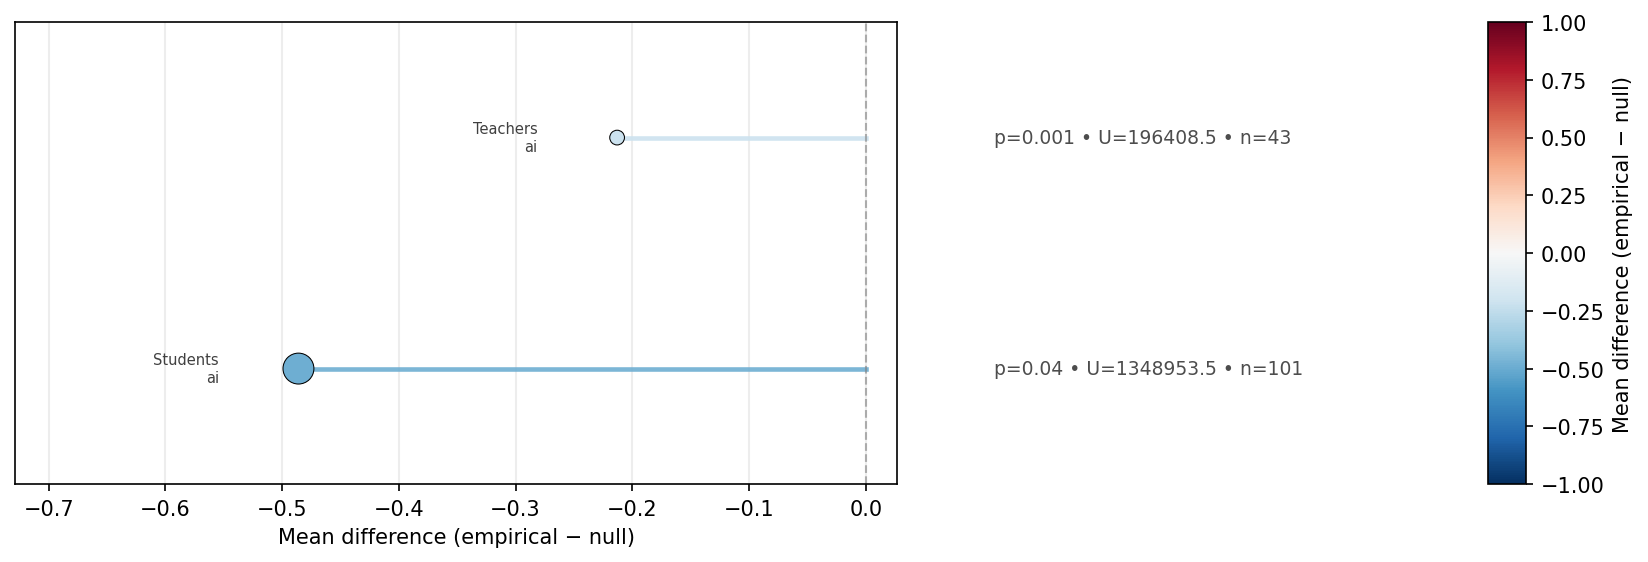

In [10]:
# Plot mean difference
plot_significant_concreteness_zmean(
    csv_filename="concreteness_analysis_table.csv",
    effect_type="mean_diff",
    order_by="effect_size",
    effect_signed=True,
    point_labels_fontsize=7
)

Saved: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/figures/significant_concreteness_summary_mean.png
Saved: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/figures/significant_concreteness_summary_mean.svg


(<Figure size 1950x600 with 3 Axes>,
 (<Axes: xlabel='Z-score (empirical vs. null)'>,
  <Axes: >,
  <Axes: ylabel='Z-score (empirical vs. null)'>),
       group keyword  p_value  u_statistic  median_empirical  median_random  \
 1  Students      ai    0.040    1348953.5             2.557           2.81   
 0  Teachers      ai    0.001     196408.5             2.210           2.83   
 
    median_diff    n  empirical_mean  null_mean  null_std  z_score  z_p_value  \
 1       -0.253  101           2.764      2.977     0.104   -2.039      0.041   
 0       -0.620   43           2.483      2.969     0.157   -3.096      0.002   
 
    ci_low_param  ci_high_param  ci_low_empirical  ci_high_empirical  cohen_d  \
 1         2.772          3.181             2.771              3.181    0.217   
 0         2.662          3.277             2.700              3.330    0.503   
 
    cliffs_delta __label_plain  
 1         0.118  Students\nai  
 0         0.292  Teachers\nai  )

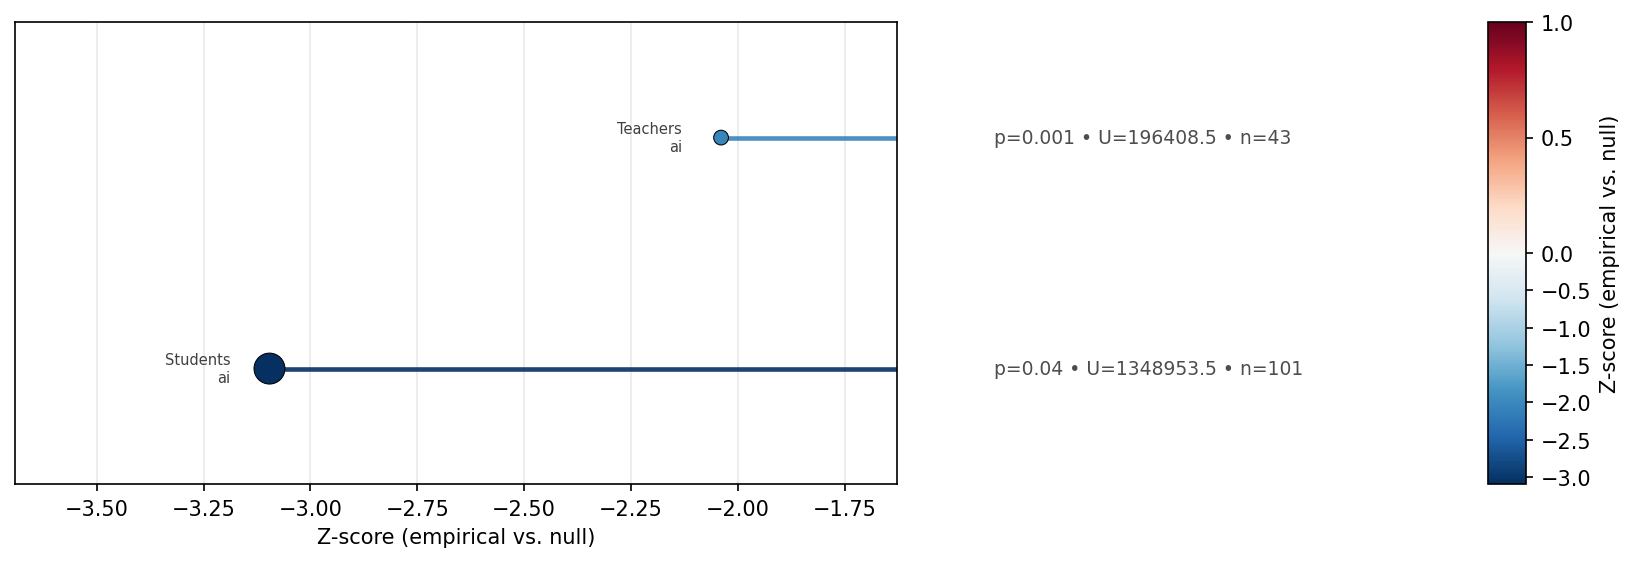

In [11]:
# Plot z-score
plot_significant_concreteness_zmean(
    csv_filename="concreteness_analysis_table.csv",
    effect_type="z_score",
    order_by="effect_size",
    effect_signed=True,
    point_labels_fontsize=7
)

Saved: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/figures/significant_concreteness_summary_mediandiff.png
Saved: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/figures/significant_concreteness_summary_mediandiff.svg


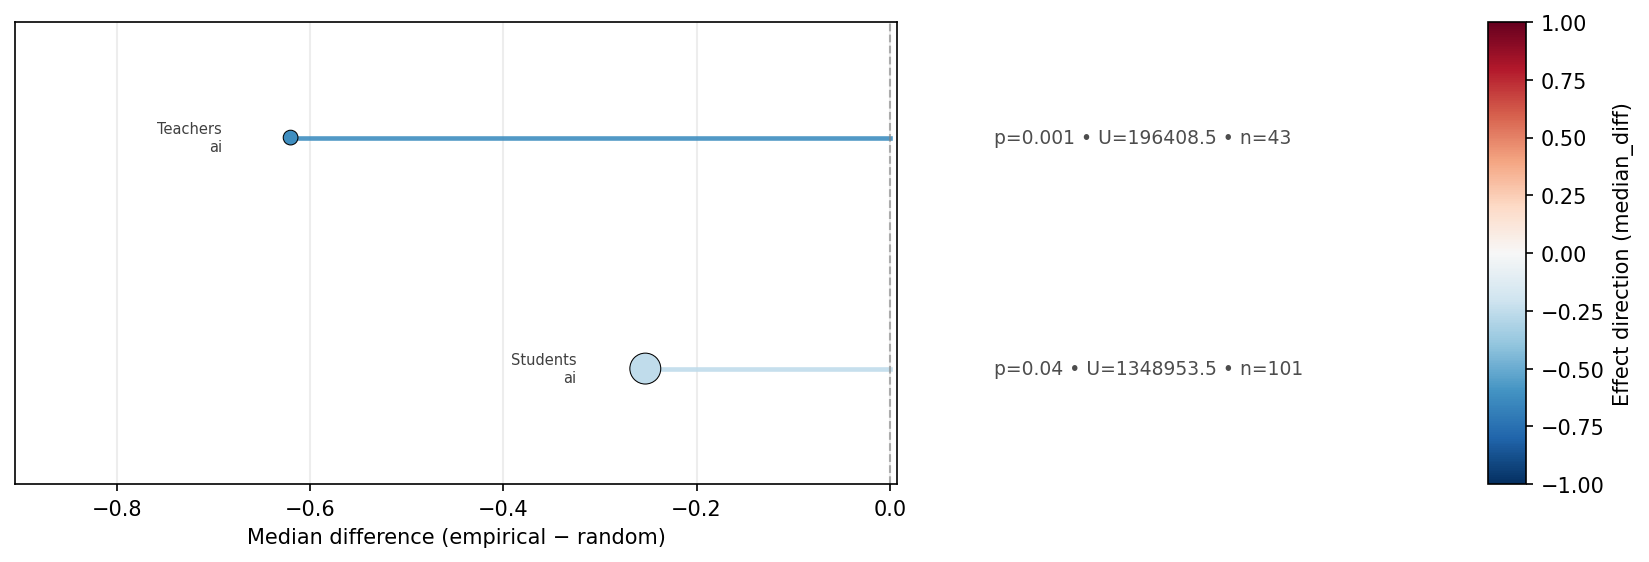

In [12]:
# Example usage (reads the CSV created above and plots it):
_ = plot_significant_concreteness_mediandiff(
    csv_filename="concreteness_analysis_table.csv",
    order_by="effect_size",
    effect_signed=True,
    point_labels_fontsize=7
)

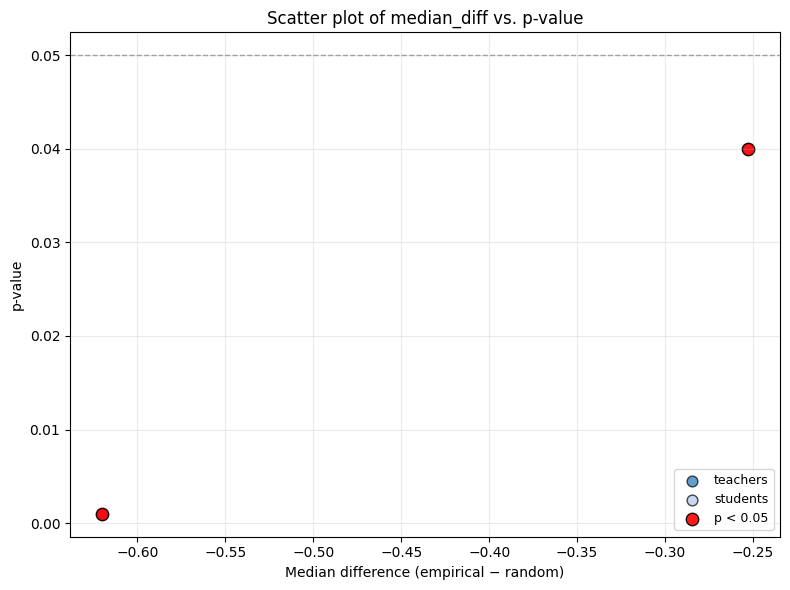

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Scatter plot of median_diff vs. p-value'}, xlabel='Median difference (empirical − random)', ylabel='p-value'>)

In [13]:
plot_median_diff_vs_pvalue(csv_filename="concreteness_analysis_table.csv", color_by="group", significance_threshold=0.05)

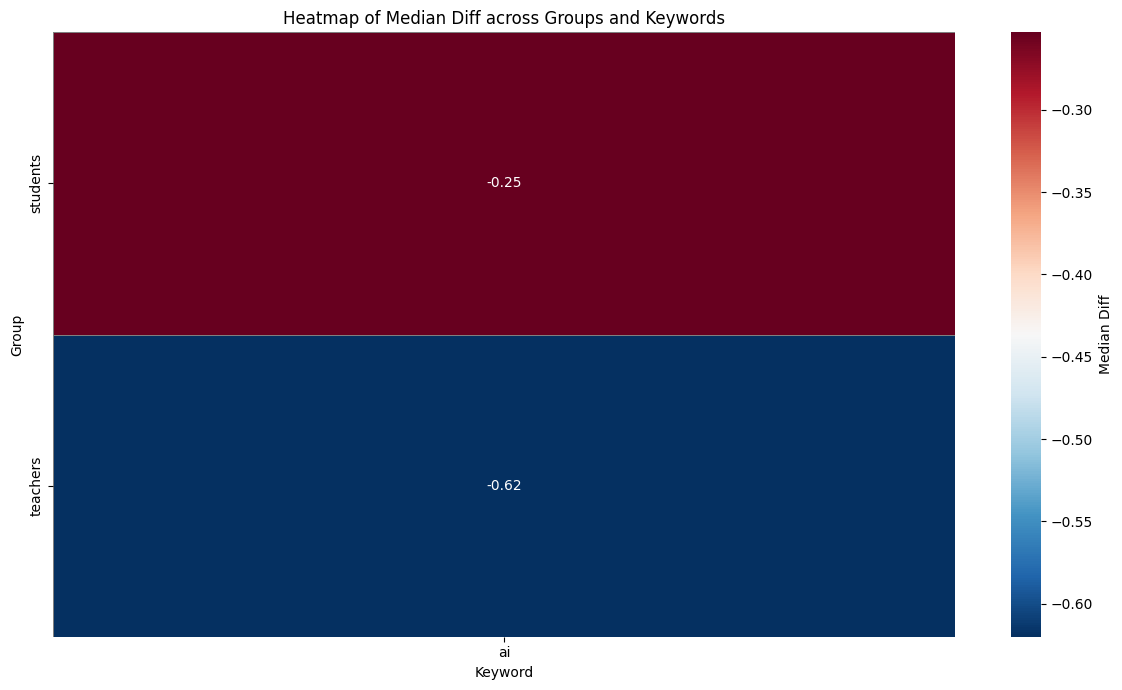

<Axes: title={'center': 'Heatmap of Median Diff across Groups and Keywords'}, xlabel='Keyword', ylabel='Group'>

In [14]:
plot_concreteness_heatmap(csv_filename="concreteness_analysis_table.csv", value="median_diff")

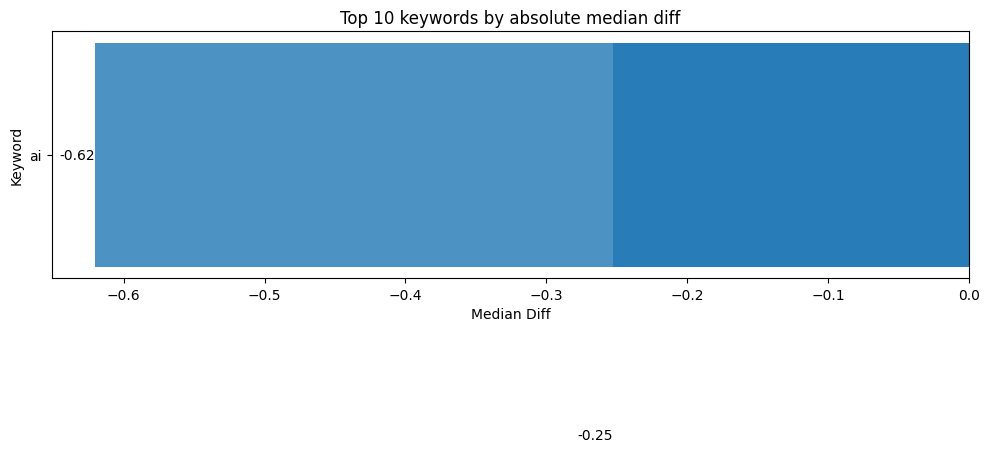

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'Top 10 keywords by absolute median diff'}, xlabel='Median Diff', ylabel='Keyword'>)

In [15]:
plot_top_effects_bar(csv_filename="concreteness_analysis_table.csv", value="median_diff", group_by="keyword", top_n=10)

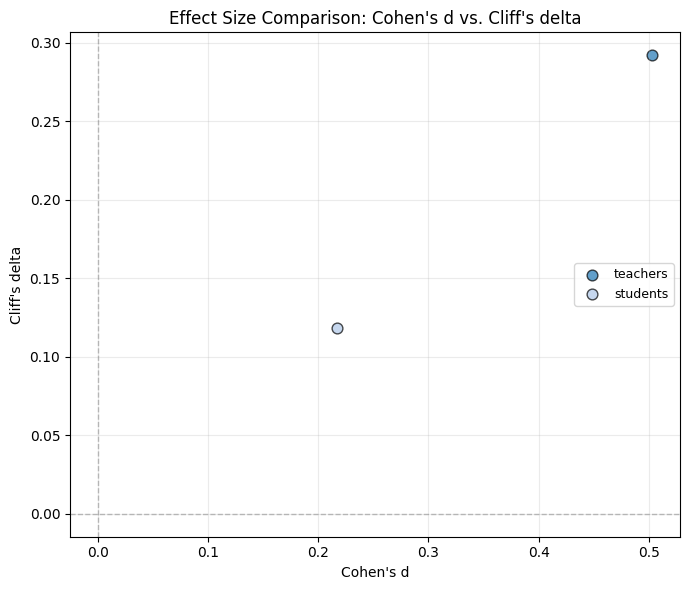

(<Figure size 700x600 with 1 Axes>,
 <Axes: title={'center': "Effect Size Comparison: Cohen's d vs. Cliff's delta"}, xlabel="Cohen's d", ylabel="Cliff's delta">)

In [16]:
plot_effect_size_comparison(csv_filename="concreteness_analysis_table.csv", color_by="group")

In [17]:
def split_concreteness_tables_by_median(
    data_import_path: Path | str,
    files_output_dir: Path | str,
    out_prefix: str = "concreteness_split_by_median",
    decimals: int = 3
) -> Dict[str, Any]:
    """
    Reads the main concreteness CSV, splits it into 'more concrete' and 'less concrete'
    tables, and exports them as properly formatted LaTeX files.
    """
    # Helper functions
    def _prettyfy_group(s: str) -> str:
        s = str(s).replace("_", " ").replace("-", " ").strip()
        return s[:1].upper() + s[1:] if s else s

    def _prettyfy_keyword(s: str) -> str:
        return str(s).replace("_", " ").strip()
    def _shorten(s: str, n: int) -> str:
        return s if len(s) <= n else s[: max(1, n - 1)] + "…"
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }
    def esc(s: str) -> str:
        s = "" if s is None else str(s)
        return "".join(specials.get(ch, ch) for ch in s)

    path = Path(data_import_path)
    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    # 1. Ensure effect column exists
    if "median_diff" not in df.columns:
        if {"median_empirical", "median_random"} <= set(df.columns):
            df["median_diff"] = df["median_empirical"] - df["median_random"]
        else:
            raise ValueError("No 'median_diff' and missing medians to compute it.")
    
    # Add mean_diff column if not present
    if "mean_diff" not in df.columns and {"empirical_mean", "null_mean"} <= set(df.columns):
        df["mean_diff"] = df["empirical_mean"] - df["null_mean"]
    
    # Single count column n
    if "n" not in df.columns:
        if "n_empirical_scores" in df.columns:
            df["n"] = df["n_empirical_scores"]
        else:
            df["n"] = pd.NA

    # 2. Rename effect columns for LaTeX before filtering/sorting
    df = df.rename(columns={
        "median_diff": r"$\Delta$M",
        "mean_diff": r"$\Delta$Mean"
    })

    # 3. Define the exact column order
    final_cols = [
        "group", "keyword", "n",                           # 3 columns (Left)
        r"$\Delta$M", "p_value", "u_statistic",             # 3 columns (Right) - Mann-Whitney
        r"$\Delta$Mean", "z_p_value", "cohen_d", "cliffs_delta", "z_score",  # 5 columns (Right) - Means Test Stats
        "empirical_mean", "null_mean", "null_std"              # 3 columns (Right) - Means Test Descriptives
    ]
    
    present = [c for c in final_cols if c in df.columns]
    df = df[present].copy()

    # Round numeric columns
    for c in df.select_dtypes(include=["number"]).columns:
        df[c] = df[c].round(decimals)

    # Prettify + escape string columns (Data Only)
    if "group" in df.columns:
        df["group"] = df["group"].map(_prettyfy_group).map(esc)
    if "keyword" in df.columns:
        df["keyword"] = df["keyword"].map(_prettyfy_keyword).map(esc)

    # Split by sign of $\Delta$M and sort
    more_df = df[df[r"$\Delta$M"] > 0].sort_values(r"$\Delta$M", ascending=False).copy()
    less_df = df[df[r"$\Delta$M"] < 0].sort_values(r"$\Delta$M", ascending=True).copy()

    # Helper to write LaTeX with correct alignment and header escaping
    def write_tex(sub_df: pd.DataFrame, caption: str, label: str, out_name: str) -> Path:
        if sub_df.empty:
            print(f"Skipping {out_name}: DataFrame is empty.")
            return None

        sub_df_latex = sub_df.copy()
        # Custom column names for split tables
        # Custom column names using standard statistical notation
        header_map = {
            "group": "Group",
            "keyword": "Keyword",
            "n": "N",
            r"$\Delta$M": r"$\Delta M$", # Difference in Medians
            "p_value": r"$p_{\text{MW}}$", # MW p-value
            "u_statistic": r"$U$",
            r"$\Delta$Mean": r"$\Delta \bar{x}$", # Difference in Sample Means
            "z_p_value": r"$p_{Z}$", # Z-test p-value
            "cohen_d": r"Cohen's $d$",
            "cliffs_delta": r"Cliff's $\delta$",
            "z_score": r"$Z$",
            "empirical_mean": r"$\bar{x}$", # Empirically observed sample mean
            "null_mean": r"$\hat{\mu}_0$", # Estimated null mean
            "null_std": r"$\hat{\sigma}_0$" # Estimated null std
        }
        sub_df_latex.rename(columns={k: v for k, v in header_map.items() if k in sub_df_latex.columns}, inplace=True)
        sub_df_latex.columns = [
            c.replace("_", r"\_") if "$" not in c else c 
            for c in sub_df_latex.columns
        ]
        col_fmt = "llr|rrr|rrrrrrrr"
        latex_core = sub_df_latex.to_latex(
            index=False,
            escape=False,
            column_format=col_fmt,
            float_format=lambda x: f"{x:.{decimals}f}",
            bold_rows=False,
            longtable=False,
            caption=None, label=None,
            header=True
        ).strip()
        body = (
            "\\begin{table}[htbp]\n"
            "\\centering\n"
            "\\small\n"
            "\\caption{" + caption + "}\n"
            f"\\label{{{label}}}\n"
            "\\resizebox{\\textwidth}{!}{\n" 
            + latex_core +
            "\n}\n"
            "\\end{table}\n"
        )
        out_path = Path(files_output_dir) / out_name
        out_path.write_text(body, encoding="utf-8")
        print(f"Wrote LaTeX table: {out_path}")
        return out_path

    more_tex = write_tex(
        more_df,
        caption="Frames more concrete than random, ordered by $\\Delta{Med}$",
        label="tab:concreteness_more",
        out_name=f"{out_prefix}_more_concrete.tex",
    )
    less_tex = write_tex(
        less_df,
        caption="Frames less concrete than random, ordered by $\\Delta{Med}$",
        label="tab:concreteness_less",
        out_name=f"{out_prefix}_less_concrete.tex",
    )

    return {
        "more_df": more_df,
        "less_df": less_df,
        "more_tex_path": more_tex,
        "less_tex_path": less_tex,
    }

'''
# Example call
res = split_concreteness_tables_by_median(
    data_import_path=Path(files_output_dir) / "concreteness_analysis_table.csv",
    files_output_dir=files_output_dir
)'''

'\n# Example call\nres = split_concreteness_tables_by_median(\n    data_import_path=Path(files_output_dir) / "concreteness_analysis_table.csv",\n    files_output_dir=files_output_dir\n)'

In [18]:
def split_concreteness_tables_by_mean_mw(
    data_import_path: Path | str,
    files_output_dir: Path | str,
    out_prefix: str = "concreteness_split_by_mean",
    decimals: int = 3
) -> Dict[str, Any]:
    """
    Reads the main concreteness CSV, splits it into 'more concrete' and 'less concrete'
    tables by mean difference, and exports them as properly formatted LaTeX files.
    """
    # Helper functions
    def _prettyfy_group(s: str) -> str:
        s = str(s).replace("_", " ").replace("-", " ").strip()
        return s[:1].upper() + s[1:] if s else s

    def _prettyfy_keyword(s: str) -> str:
        return str(s).replace("_", " ").strip()
    def _shorten(s: str, n: int) -> str:
        return s if len(s) <= n else s[: max(1, n - 1)] + "…"
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }
    def esc(s: str) -> str:
        s = "" if s is None else str(s)
        return "".join(specials.get(ch, ch) for ch in s)

    path = Path(data_import_path)
    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    # 1. Ensure effect column exists
    if "mean_diff" not in df.columns and {"empirical_mean", "null_mean"} <= set(df.columns):
        df["mean_diff"] = df["empirical_mean"] - df["null_mean"]
    # Single count column n
    if "n" not in df.columns:
        if "n_empirical_scores" in df.columns:
            df["n"] = df["n_empirical_scores"]
        else:
            df["n"] = pd.NA
    # 2. Rename effect columns for LaTeX before filtering/sorting
    df = df.rename(columns={
        "mean_diff": r"$\Delta$Mean"
    })
    # 3. Define the exact column order
    final_cols = [
        "group", "keyword", "n",                           # 3 columns (Left)
        r"$\Delta$Mean", "p_value", "u_statistic",             # 3 columns (Right) - Mann-Whitney
        "z_p_value", "cohen_d", "cliffs_delta", "z_score",  # 4 columns (Right) - Means Test Stats
        "empirical_mean", "null_mean", "null_std"              # 3 columns (Right) - Means Test Descriptives
    ]
    present = [c for c in final_cols if c in df.columns]
    df = df[present].copy()
    # Round numeric columns
    for c in df.select_dtypes(include=["number"]).columns:
        df[c] = df[c].round(decimals)
    # Prettify + escape string columns (Data only)
    if "group" in df.columns:
        df["group"] = df["group"].map(_prettyfy_group).map(esc)
    if "keyword" in df.columns:
        df["keyword"] = df["keyword"].map(_prettyfy_keyword).map(esc)
    # Split by sign of $\Delta$Mean and sort
    more_df = df[df[r"$\Delta$Mean"] > 0].sort_values(r"$\Delta$Mean", ascending=False).copy()
    less_df = df[df[r"$\Delta$Mean"] < 0].sort_values(r"$\Delta$Mean", ascending=True).copy()
    # Helper to write LaTeX with correct alignment and header escaping
    def write_tex(sub_df: pd.DataFrame, caption: str, label: str, out_name: str) -> Path:
        if sub_df.empty:
            print(f"Skipping {out_name}: DataFrame is empty.")
            return None
        sub_df_latex = sub_df.copy()
        header_map = {
            "group": "Group",
            "keyword": "Keyword",
            "n": "N",
            r"$\Delta$Mean": r"$\Delta \bar{x}$", # Difference in Sample Means
            "p_value": r"$p_{\text{MW}}$", # MW p-value
            "u_statistic": r"$U$",
            "z_p_value": r"$p_{Z}$", # Z-test p-value
            "cohen_d": r"Cohen's $d$",
            "cliffs_delta": r"Cliff's $\delta$",
            "z_score": r"$Z$",
            "empirical_mean": r"$\bar{x}$", # Empirically observed sample mean
            "null_mean": r"$\hat{\mu}_0$", # Estimated null mean
            "null_std": r"$\hat{\sigma}_0$" # Estimated null std
        }
        sub_df_latex.rename(columns={k: v for k, v in header_map.items() if k in sub_df_latex.columns}, inplace=True)
        sub_df_latex.columns = [
            c.replace("_", r"\_") if "$" not in c else c 
            for c in sub_df_latex.columns
        ]
        col_fmt = "llr|rrr|rrrrrrrr"
        latex_core = sub_df_latex.to_latex(
            index=False,
            escape=False,
            column_format=col_fmt,
            float_format=lambda x: f"{x:.{decimals}f}",
            bold_rows=False,
            longtable=False,
            caption=None, label=None,
            header=True
        ).strip()
        body = (
            "\\begin{table}[htbp]\n"
            "\\centering\n"
            "\\small\n"
            "\\caption{" + caption + "}\n"
            f"\\label{{{label}}}\n"
            "\\resizebox{\\textwidth}{!}{\n" 
            + latex_core +
            "\n}\n"
            "\\end{table}\n"
        )
        out_path = Path(files_output_dir) / out_name
        out_path.write_text(body, encoding="utf-8")
        print(f"Wrote LaTeX table: {out_path}")
        return out_path

    more_tex = write_tex(
        more_df,
        caption="Frames more concrete than random, ordered by $\\Delta\\bar{x}$",
        label="tab:concreteness_more",
        out_name=f"{out_prefix}_more_concrete.tex",
    )
    less_tex = write_tex(
        less_df,
        caption="Frames less concrete than random, ordered by $\\Delta\\bar{x}$",
        label="tab:concreteness_less",
        out_name=f"{out_prefix}_less_concrete.tex",
    )

    return {
        "more_df": more_df,
        "less_df": less_df,
        "more_tex_path": more_tex,
        "less_tex_path": less_tex,
    }


def split_concreteness_tables_by_mean(
    data_import_path: Path | str,
    files_output_dir: Path | str,
    out_prefix: str = "concreteness_split_by_mean_custom",
    decimals: int = 2,
    z_alpha: float = 1.96  # 5% significance, two-tailed
) -> Dict[str, Any]:
    """
    Custom split of concreteness tables by mean difference, following specific rules:
    - Drops Mann-Whitney columns
    - Uses k (node degree) instead of N
    - Effect column: $\bar{x}-\hat{\mu}_0$
    - Rounds all values to 2 decimals
    - Keeps only significant rows with |Z| > 1.96 (5% level)
    - First columns: Group, Keyword, k
    - Last columns: Cohen's d, Z, $\bar{x}$, Cliff's delta
    """
    # Helper functions
    def _prettyfy_group(s: str) -> str:
        s = str(s).replace("_", " ").replace("-", " ").strip()
        return s[:1].upper() + s[1:] if s else s

    def _prettyfy_keyword(s: str) -> str:
        return str(s).replace("_", " ").strip()
    def _shorten(s: str, n: int) -> str:
        return s if len(s) <= n else s[: max(1, n - 1)] + "…"
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }
    def esc(s: str) -> str:
        s = "" if s is None else str(s)
        return "".join(specials.get(ch, ch) for ch in s)
    
    path = Path(data_import_path)
    if not path.exists():
        raise FileNotFoundError(path)
    df = pd.read_csv(path)

    # Compute mean difference column
    if "mean_diff" not in df.columns and {"empirical_mean", "null_mean"} <= set(df.columns):
        df["mean_diff"] = df["empirical_mean"] - df["null_mean"]  # minus sign as requested

    # Filter by |Z| > 1.96
    if "$Z$" in df.columns:
        df = df[df["$Z$"].abs() > z_alpha].copy()

    '''# Apply acronyms to 'group' column
    df = apply_acronyms(
        df,
        lookup_map=participants_map_rassereno
    )'''

    # print the dataframe
    print(f"DataFrame after filtering by |Z| > {z_alpha}:")
    print(df)

    # Select columns to retrieve from DataFrame
    final_cols = [
        "group", "keyword", "n", "mean_diff", "z_score", "cohen_d", "empirical_mean", "cliffs_delta"
    ]
    present = [c for c in final_cols if c in df.columns]
    df = df[present].copy()

    # Round all numeric columns to 2 decimals
    for c in df.select_dtypes(include=["number"]).columns:
        df[c] = df[c].round(decimals)

    # Prettify and escape string columns
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }

    def esc(s: str) -> str:
        return "".join(specials.get(ch, ch) for ch in str(s))
    if "group" in df.columns:
        df["group"] = df["group"].map(lambda s: s.replace("_", " ").capitalize()).map(esc)
    if "keyword" in df.columns:
        df["keyword"] = df["keyword"].map(lambda s: s.replace("_", " ")).map(esc)

    # Translate 'keyword' column from Italian to English
    translate_column(
        df = df,
        source_lang = 'italian',
        target_lang = 'english',
        col = 'keyword'
    )

    #titlecase the 'keyword' column
    if 'keyword' in df.columns:
        df['keyword'] = df['keyword'].str.title()

    # Split by sign of effect and sort
    more_df = df[df["mean_diff"] > 0].sort_values("mean_diff", ascending=False).copy()
    less_df = df[df["mean_diff"] < 0].sort_values("mean_diff", ascending=True).copy()

    # Rename columns after subsetting
    more_df = more_df.rename(columns={
        "mean_diff": r"$\bar{x}-\hat{\mu}_0$",
        "cohen_d": r"Cohen's $d$",
        "z_score": r"$Z$",
        "empirical_mean": r"$\bar{x}$",
        "cliffs_delta": r"Cliff's $\delta$",
        "n": "k"
    })

    # Rename columns after subsetting
    less_df = less_df.rename(columns={
        "mean_diff": r"$\bar{x}-\hat{\mu}_0$",
        "cohen_d": r"Cohen's $d$",
        "z_score": r"$Z$",
        "empirical_mean": r"$\bar{x}$",
        "cliffs_delta": r"Cliff's $\delta$",
        "n": "k"
    })

    # Helper to write LaTeX with correct alignment and header escaping
    def write_tex(sub_df: pd.DataFrame, caption: str, label: str, out_name: str) -> Path:
        if sub_df.empty:
            print(f"Skipping {out_name}: DataFrame is empty.")
            return None
        col_fmt = "llr|rrrrr"
        latex_core = sub_df.to_latex(
            index=False,
            escape=False,
            column_format=col_fmt,
            float_format=lambda x: f"{x:.{decimals}f}",
            bold_rows=False,
            longtable=False,
            caption=None,
            label=None,
            header=True
        ).strip()
        body = (
            "\\begin{table}[htbp]\n"
            "\\centering\n"
            "\\small\n"
            "\\caption{" + caption + "}\n"
            f"\\label{{{label}}}\n"
            "\\resizebox{\\textwidth}{!}{\n" 
            + latex_core +
            "\n}\n"
            "\\end{table}\n"
        )
        out_path = Path(files_output_dir) / out_name
        out_path.write_text(body, encoding="utf-8")
        print(f"Wrote LaTeX table: {out_path}")
        return out_path

    more_tex = write_tex(
        more_df,
        caption="Frames more concrete than random ordered by $\\bar{x} - \\hat{\\mu}_0$ (significant $|Z| > 1.96$)",
        label="tab:concreteness_more_mean_custom",
        out_name=f"{out_prefix}_more_concrete.tex",
    )
    less_tex = write_tex(
        less_df,
        caption="Frames less concrete than random ordered by $\\bar{x} - \\hat{\\mu}_0$ (significant $|Z| > 1.96$)",
        label="tab:concreteness_less_mean_custom",
        out_name=f"{out_prefix}_less_concrete.tex",
    )
    return {
        "more_df": more_df,
        "less_df": less_df,
        "more_tex_path": more_tex,
        "less_tex_path": less_tex,
    }

In [19]:
# Create the split LaTeX tables (mean-based, custom formatting)
# Produces two files:
#  - concreteness_split_by_mean_custom_more_concrete.tex
#  - concreteness_split_by_mean_custom_less_concrete.tex
res_mean_custom = split_concreteness_tables_by_mean(
    data_import_path=Path(files_output_dir) / "concreteness_analysis_table.csv",
    files_output_dir=files_output_dir,
    out_prefix="concreteness_split_by_mean_custom",
    decimals=2,
    z_alpha=1.96,
)

# Optional: display previews
try:
    display(res_mean_custom.get("more_df"))
    display(res_mean_custom.get("less_df"))
except Exception:
    pass


DataFrame after filtering by |Z| > 1.96:
      group keyword  p_value  u_statistic  median_empirical  median_random  \
0  teachers      ai    0.001     196408.5             2.210           2.83   
1  students      ai    0.040    1348953.5             2.557           2.81   

   median_diff    n  empirical_mean  null_mean  null_std  z_score  z_p_value  \
0       -0.620   43           2.483      2.969     0.157   -3.096      0.002   
1       -0.253  101           2.764      2.977     0.104   -2.039      0.041   

   ci_low_param  ci_high_param  ci_low_empirical  ci_high_empirical  cohen_d  \
0         2.662          3.277             2.700              3.330    0.503   
1         2.772          3.181             2.771              3.181    0.217   

   cliffs_delta  mean_diff  
0         0.292     -0.486  
1         0.118     -0.213  
Translating 1 unique keywords...
Translation complete.
Skipping concreteness_split_by_mean_custom_more_concrete.tex: DataFrame is empty.
Wrote LaTeX table:

,group,keyword,k,$\bar{x}-\hat{\mu}_0$,$Z$,Cohen's $d$,$\bar{x}$,Cliff's $\delta$


,group,keyword,k,$\bar{x}-\hat{\mu}_0$,$Z$,Cohen's $d$,$\bar{x}$,Cliff's $\delta$
0,Teachers,To The,43,-0.49,-3.10,0.50,2.48,0.29
1,Students,To The,101,-0.21,-2.04,0.22,2.76,0.12


In [20]:
# New function: export LaTeX table with confidence intervals only
def export_latex_confidence_intervals_table(
    source_csv: str,
    files_output_dir: str,
    out_tex: str = "confidence_intervals_table.tex",
    decimals: int = 3
):
    """
    Export a LaTeX table containing only the confidence interval columns.
    """
    path = Path(files_output_dir) / source_csv
    if not path.exists():
        raise FileNotFoundError(path)
    df = pd.read_csv(path)
    ci_cols = [
        "group", "keyword",
        "ci_low_param", "ci_high_param", "ci_low_empirical", "ci_high_empirical"
    ]
    present = [c for c in ci_cols if c in df.columns]
    df = df[present].copy()
    for c in df.select_dtypes(include=["number"]).columns:
        df[c] = df[c].round(decimals)
    # Escape LaTeX special chars
    specials = {
        "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
        "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}", "\\": r"\textbackslash{}"
    }
    def esc(s: str) -> str:
        return "".join(specials.get(ch, ch) for ch in str(s))
    df.columns = [esc(c) for c in df.columns]
    for col in df.select_dtypes(include=["object"]).columns:
        df[col] = df[col].map(esc)
    col_fmt = "llrrrr"
    latex_core = df.to_latex(
        index=False,
        float_format=lambda x: f"{x:.{decimals}f}",
        escape=False,
        column_format=col_fmt
    ).strip()
    body = (
        "\\begin{table}[htbp]\n"
        "\\centering\n"
        "\\small\n"
        "\\caption{Confidence intervals for each group and keyword}\n"
        f"\\label{{tab:confidence_intervals}}\n"
        "\\resizebox{\\textwidth}{!}{%\n" + latex_core + "\n}\n"
        "\\end{table}\n"
    )
    out_path = Path(files_output_dir) / out_tex
    out_path.write_text(body, encoding="utf-8")
    print(f"Wrote LaTeX confidence intervals table: {out_path}")
    return out_path

In [21]:
# Example call
export_latex_confidence_intervals_table(
    source_csv="concreteness_analysis_table.csv",
    files_output_dir=files_output_dir,
    out_tex="confidence_intervals_table.tex",
    decimals=3
)

Wrote LaTeX confidence intervals table: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/confidence_intervals_table.tex


PosixPath('../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/confidence_intervals_table.tex')

# Normality test

In [22]:
def create_normality_table(
    output_filename: str = "normality_analysis_table.csv",
    decimals: int = 3,
    alpha: float = 0.05,
    method: str | None = None,
):
    """Runs Shapiro-Wilk test for normality on empirical and random scores from each JSON file.

    This notebook is designed to post-process the JSONs written by `bfmn_pipeline` under:
      out/<project_name>/<method>/<group>_bfmns/analysis/*_concreteness_analysis.json

    Parameters
    ----------
    output_filename : str
        CSV filename to export (written into `files_output_dir`).
    decimals : int
        Decimal places to round numeric outputs.
    alpha : float
        Significance level for normality decision (p >= alpha -> normal True).
    method : str | None
        Which pipeline mode to read from: 'aggregated' or 'individual'.
        If None, uses the first entry in `methods`.
    """

    # Decide which pipeline method folder to read
    if method is None:
        method = next(iter(methods)) if isinstance(methods, set) and len(methods) else "aggregated"
    method = (method or "").strip().lower()

    search_root = Path(pipeline_out_root) / method
    if not search_root.exists():
        print(f"Pipeline output folder not found: {search_root}")
        return pd.DataFrame()

    pattern = "**/analysis/*_concreteness_analysis.json"
    json_paths = sorted(search_root.glob(pattern))

    records = []
    for jp in json_paths:
        try:
            with jp.open("r", encoding="utf-8") as f:
                data = json.load(f)
        except Exception:
            continue

        # Parse group + keyword
        parent_group = jp.parent.parent.name  # .../<group>_bfmns/analysis/<file>
        parent_group = parent_group[:-6] if parent_group.endswith("_bfmns") else parent_group

        stem = jp.stem
        suffix = "_concreteness_analysis"
        if not stem.endswith(suffix):
            continue
        stem = stem[: -len(suffix)]

        if stem.startswith(parent_group + "_"):
            keyword = stem[len(parent_group) + 1 :]
            group = parent_group
        else:
            keyword = stem.split("_")[-1]
            group = parent_group

        empirical_scores = data.get("empirical_scores", [])
        random_scores = data.get("random_scores", [])

        n_empirical = len(empirical_scores)
        n_random = len(random_scores)

        # Shapiro-Wilk test for normality
        if n_empirical > 2:
            shapiro_emp = stats.shapiro(empirical_scores)
            shapiro_stat_empirical = shapiro_emp.statistic
            shapiro_p_empirical = shapiro_emp.pvalue
        else:
            shapiro_stat_empirical = None
            shapiro_p_empirical = None
        if n_random > 2:
            shapiro_rand = stats.shapiro(random_scores)
            shapiro_stat_random = shapiro_rand.statistic
            shapiro_p_random = shapiro_rand.pvalue
        else:
            shapiro_stat_random = None
            shapiro_p_random = None

        # Boolean decision: True if normality not rejected (p >= alpha), else False; None if test not run
        shapiro_normal_empirical = (
            (shapiro_p_empirical is not None) and (shapiro_p_empirical >= alpha)
        ) if shapiro_p_empirical is not None else None
        shapiro_normal_random = (
            (shapiro_p_random is not None) and (shapiro_p_random >= alpha)
        ) if shapiro_p_random is not None else None

        records.append({
            "method": method,
            "group": group,
            "keyword": keyword,
            "n_empirical": n_empirical,
            "n_random": n_random,
            "shapiro_stat_empirical": shapiro_stat_empirical,
            "shapiro_p_empirical": shapiro_p_empirical,
            "shapiro_stat_random": shapiro_stat_random,
            "shapiro_p_random": shapiro_p_random,
            "shapiro_normal_empirical": shapiro_normal_empirical,
            "shapiro_normal_random": shapiro_normal_random,
        })

    df = pd.DataFrame(records)
    if df.empty:
        print("No concreteness analysis files found.")
        return df

    # Round numeric columns
    num_cols = df.select_dtypes(include=["number"]).columns
    for c in num_cols:
        df[c] = df[c].round(decimals)

    # Sort by group, keyword
    df.sort_values(["group", "keyword"], inplace=True)

    out_path = Path(files_output_dir) / output_filename
    try:
        df.to_csv(out_path, index=False, encoding="utf-8")
    except Exception as e:
        print(f"Failed to write CSV via pandas: {e}")

    print(f"Exported to: {out_path}")
    try:
        display(df)
    except Exception:
        pass

    return df


def analyze_random_normality_and_plots(
    output_filename: str = "normality_analysis_table_anderson_random.csv",
    decimals: int = 3,
    figures_subdir: str = "normality_random",
    method: str | None = None,
):
    """For each concreteness JSON, analyze the null/random distribution only.

    Reads bfmn_pipeline outputs from:
      out/<project_name>/<method>/<group>_bfmns/analysis/*_concreteness_analysis.json

    For each (group, keyword):
      - Standardize random_scores using sample mean and std.
      - Run Anderson-Darling test for normality on standardized scores.
      - Save histogram and Q–Q plot of standardized scores.
      - Collect summary statistics and test results into a CSV.
    """

    if method is None:
        method = next(iter(methods)) if isinstance(methods, set) and len(methods) else "aggregated"
    method = (method or "").strip().lower()

    search_root = Path(pipeline_out_root) / method
    if not search_root.exists():
        print(f"Pipeline output folder not found: {search_root}")
        return pd.DataFrame()

    json_paths = sorted(search_root.glob("**/analysis/*_concreteness_analysis.json"))

    fig_dir = Path(figures_output_dir) / figures_subdir
    fig_dir.mkdir(parents=True, exist_ok=True)

    records = []
    for jp in json_paths:
        try:
            with jp.open("r", encoding="utf-8") as f:
                data = json.load(f)
        except Exception:
            continue

        parent_group = jp.parent.parent.name
        parent_group = parent_group[:-6] if parent_group.endswith("_bfmns") else parent_group

        stem = jp.stem
        suffix = "_concreteness_analysis"
        if not stem.endswith(suffix):
            continue
        stem = stem[: -len(suffix)]

        if stem.startswith(parent_group + "_"):
            keyword = stem[len(parent_group) + 1 :]
            group = parent_group
        else:
            keyword = stem.split("_")[-1]
            group = parent_group

        random_scores = data.get("random_scores", [])
        n_random = len(random_scores)

        if n_random < 3:
            records.append({
                "group": group,
                "keyword": keyword,
                "n_random": n_random,
                "mean_random": None,
                "std_random": None,
                "anderson_stat": None,
                "anderson_crit_15": None,
                "anderson_sig_15": None,
                "anderson_crit_10": None,
                "anderson_sig_10": None,
                "anderson_crit_5": None,
                "anderson_sig_5": None,
                "anderson_crit_2_5": None,
                "anderson_sig_2_5": None,
                "anderson_crit_1": None,
                "anderson_sig_1": None,
            })
            continue

        arr = np.asarray(random_scores, dtype=float)
        mu = float(np.mean(arr))
        sigma = float(np.std(arr, ddof=1)) if n_random > 1 else 0.0

        if sigma <= 0 or not np.isfinite(sigma):
            z = arr - mu
        else:
            z = (arr - mu) / sigma

        ad_res = stats.anderson(z, dist="norm")

        crit_map = dict(zip(ad_res.significance_level, ad_res.critical_values))
        thresh = {
            15.0: crit_map.get(15.0),
            10.0: crit_map.get(10.0),
            5.0: crit_map.get(5.0),
            2.5: crit_map.get(2.5),
            1.0: crit_map.get(1.0),
        }
        sig_flags = {lvl: (ad_res.statistic > cv) if cv is not None else None for lvl, cv in thresh.items()}

        fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=150)

        ax[0].hist(z, bins=30, density=True, alpha=0.7, color="C0")
        xlim = ax[0].get_xlim()
        xs = np.linspace(xlim[0], xlim[1], 200)
        ax[0].plot(xs, stats.norm.pdf(xs), color="red", lw=1.2, label="N(0,1)")
        ax[0].set_title(f"Histogram (std. random)\n{group} – {keyword}")
        ax[0].set_xlabel("z")
        ax[0].set_ylabel("Density")
        ax[0].legend(fontsize=8)

        stats.probplot(z, dist="norm", plot=ax[1])
        ax[1].set_title("Q–Q plot vs N(0,1)")

        safe_group = re.sub(r"[^A-Za-z0-9_]+", "_", str(group))
        safe_kw = re.sub(r"[^A-Za-z0-9_]+", "_", str(keyword))
        fname_base = f"{safe_group}_{safe_kw}_random_normality"
        png_path = fig_dir / f"{fname_base}.png"
        svg_path = fig_dir / f"{fname_base}.svg"
        fig.tight_layout()
        try:
            fig.savefig(png_path, bbox_inches="tight")
            fig.savefig(svg_path, bbox_inches="tight")
        except Exception as e:
            print(f"Failed to save normality plots for {group}/{keyword}: {e}")
        plt.close(fig)

        records.append({
            "group": group,
            "keyword": keyword,
            "n_random": n_random,
            "mean_random": mu,
            "std_random": sigma,
            "anderson_stat": float(ad_res.statistic),
            "anderson_crit_15": thresh[15.0],
            "anderson_sig_15": sig_flags[15.0],
            "anderson_crit_10": thresh[10.0],
            "anderson_sig_10": sig_flags[10.0],
            "anderson_crit_5": thresh[5.0],
            "anderson_sig_5": sig_flags[5.0],
            "anderson_crit_2_5": thresh[2.5],
            "anderson_sig_2_5": sig_flags[2.5],
            "anderson_crit_1": thresh[1.0],
            "anderson_sig_1": sig_flags[1.0],
            "hist_qq_base": fname_base,
        })

    df = pd.DataFrame(records)
    if df.empty:
        print("No concreteness analysis files found.")
        return df

    num_cols = df.select_dtypes(include=["number"]).columns
    for c in num_cols:
        df[c] = df[c].round(decimals)

    df.sort_values(["group", "keyword"], inplace=True)

    out_path = Path(files_output_dir) / output_filename
    try:
        df.to_csv(out_path, index=False, encoding="utf-8")
    except Exception as e:
        print(f"Failed to write CSV via pandas: {e}")

    print(f"Exported Anderson-Darling summary to: {out_path}")
    try:
        display(df)
    except Exception:
        pass

    return df

In [23]:
create_normality_table(
    output_filename="normality_analysis_table_shapiro.csv",
    decimals=3,
)

Exported to: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/normality_analysis_table_shapiro.csv


/home/franaz/coding/python/venvs/.rassereno-py310/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 30300.
  res = hypotest_fun_out(*samples, **kwds)
/home/franaz/coding/python/venvs/.rassereno-py310/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7200.
  res = hypotest_fun_out(*samples, **kwds)
/home/franaz/coding/python/venvs/.rassereno-py310/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 12900.
  res = hypotest_fun_out(*samples, **kwds)


,method,group,keyword,n_empirical,n_random,shapiro_stat_empirical,shapiro_p_empirical,shapiro_stat_random,shapiro_p_random,shapiro_normal_empirical,shapiro_normal_random
0,aggregated,students,ai,101,30300,0.912,0.000,0.943,0.0,False,False
1,aggregated,students,chatgpt,24,7200,0.938,0.149,0.945,0.0,True,False
2,aggregated,teachers,ai,43,12900,0.850,0.000,0.944,0.0,False,False


,method,group,keyword,n_empirical,n_random,shapiro_stat_empirical,shapiro_p_empirical,shapiro_stat_random,shapiro_p_random,shapiro_normal_empirical,shapiro_normal_random
0,aggregated,students,ai,101,30300,0.912,0.000,0.943,0.0,False,False
1,aggregated,students,chatgpt,24,7200,0.938,0.149,0.945,0.0,True,False
2,aggregated,teachers,ai,43,12900,0.850,0.000,0.944,0.0,False,False


In [24]:
# Run other normality analysis and plots
analyze_random_normality_and_plots(
    output_filename="normality_analysis_table_anderson_random.csv",
    decimals=3,
    figures_subdir="normality_random",
)

Exported Anderson-Darling summary to: ../data/out/ai_perception_all_students_005_stacked/aggregated/analysis/concreteness/normality_analysis_table_anderson_random.csv


,group,keyword,n_random,mean_random,std_random,anderson_stat,anderson_crit_15,anderson_sig_15,anderson_crit_10,anderson_sig_10,anderson_crit_5,anderson_sig_5,anderson_crit_2_5,anderson_sig_2_5,anderson_crit_1,anderson_sig_1,hist_qq_base
0,students,ai,30300,2.981,1.001,517.664,0.576,True,0.656,True,0.787,True,0.918,True,1.092,True,students_ai_random_normality
1,students,chatgpt,7200,2.993,1.005,116.672,0.576,True,0.656,True,0.787,True,0.917,True,1.091,True,students_chatgpt_random_normality
2,teachers,ai,12900,2.988,1.003,213.393,0.576,True,0.656,True,0.787,True,0.918,True,1.092,True,teachers_ai_random_normality


,group,keyword,n_random,mean_random,std_random,anderson_stat,anderson_crit_15,anderson_sig_15,anderson_crit_10,anderson_sig_10,anderson_crit_5,anderson_sig_5,anderson_crit_2_5,anderson_sig_2_5,anderson_crit_1,anderson_sig_1,hist_qq_base
0,students,ai,30300,2.981,1.001,517.664,0.576,True,0.656,True,0.787,True,0.918,True,1.092,True,students_ai_random_normality
1,students,chatgpt,7200,2.993,1.005,116.672,0.576,True,0.656,True,0.787,True,0.917,True,1.091,True,students_chatgpt_random_normality
2,teachers,ai,12900,2.988,1.003,213.393,0.576,True,0.656,True,0.787,True,0.918,True,1.092,True,teachers_ai_random_normality
